In [239]:
import pandas as pd
import squarify, matplotlib.pyplot as plt
import seaborn as sns

### Exploratory Data Analysis and cleaning

#### EXPLORE

In [ ]:
sale = pd.read_csv('"C:\\Users\\admin\\OneDrive\\CV\\Global Electronic Retailer\\Data\\Sales.csv"')
product = pd.read_csv('"C:\\Users\\admin\\OneDrive\\CV\\Global Electronic Retailer\\Data\\Products.csv"')
customer = pd.read_csv('C:\\Users\\admin\\OneDrive\CV\\Global Electronic Retailer\\Data\\Customers.csv',encoding = 'Latin1')
exchange_rate = pd.read_csv('"C:\\Users\\admin\\OneDrive\\CV\\Global Electronic Retailer\\Data\\Exchange_Rates.csv"')
store = pd.read_csv('"C:\\Users\\admin\\OneDrive\CV\\Global Electronic Retailer\\Data\\Stores.csv"')

In [241]:
sale.head(3)

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD


In [242]:
product.head(3)

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,$6.62,$12.99,101,MP4&MP3,1,Audio
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,$6.62,$12.99,101,MP4&MP3,1,Audio
2,3,Contoso 1G MP3 Player E100 White,Contoso,White,$7.40,$14.52,101,MP4&MP3,1,Audio


In [243]:
customer.head(3)

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,7/3/1939
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,9/27/1979
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,5/26/1947


In [244]:
store[['StoreKey','Country']]

,StoreKey,Country
0,1,Australia
1,2,Australia
2,3,Australia
3,4,Australia
4,5,Australia
...,...,...
62,63,United States
63,64,United States
64,65,United States
65,66,United States


In [245]:
sale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Order Number   62884 non-null  int64 
 1   Line Item      62884 non-null  int64 
 2   Order Date     62884 non-null  object
 3   Delivery Date  13165 non-null  object
 4   CustomerKey    62884 non-null  int64 
 5   StoreKey       62884 non-null  int64 
 6   ProductKey     62884 non-null  int64 
 7   Quantity       62884 non-null  int64 
 8   Currency Code  62884 non-null  object
dtypes: int64(6), object(3)
memory usage: 4.3+ MB


In [246]:
product.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ProductKey      2517 non-null   int64 
 1   Product Name    2517 non-null   object
 2   Brand           2517 non-null   object
 3   Color           2517 non-null   object
 4   Unit Cost USD   2517 non-null   object
 5   Unit Price USD  2517 non-null   object
 6   SubcategoryKey  2517 non-null   int64 
 7   Subcategory     2517 non-null   object
 8   CategoryKey     2517 non-null   int64 
 9   Category        2517 non-null   object
dtypes: int64(3), object(7)
memory usage: 196.8+ KB


In [247]:
print(f"Sales: {sale.shape}")
print(f"Products: {product.shape}")
print(f"Customers: {customer.shape}")
print(f"Stores: {store.shape}")
print(f"Exchange Rates: {exchange_rate.shape}")

Sales: (62884, 9)
Products: (2517, 10)
Customers: (15266, 10)
Stores: (67, 5)
Exchange Rates: (11215, 3)


#### CLEANING

In [248]:
# Loại bỏ kí tự đặc biệt
for col in ['Unit Cost USD', 'Unit Price USD']:
    product[col] = product[col].astype(str).str.replace('$', '', regex = False).str.replace(',', '', regex = False).astype(float)

In [249]:
product[['Unit Cost USD','Unit Price USD']].dtypes

Unit Cost USD     float64
Unit Price USD    float64
dtype: object

In [250]:
product.head(2)

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,6.62,12.99,101,MP4&MP3,1,Audio
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,6.62,12.99,101,MP4&MP3,1,Audio


In [251]:
#Chuẩn hóa ngày tháng 
sale['Order Date'] = pd.to_datetime(sale['Order Date'])
sale['Delivery Date'] = pd.to_datetime(sale['Delivery Date'])
sale[['Delivery Date', 'Order Date']].dtypes

Delivery Date    datetime64[ns]
Order Date       datetime64[ns]
dtype: object

In [252]:
sale['Year'] = sale['Order Date'].dt.year
sale['YearMonth'] = sale['Order Date'].dt.to_period('M')

In [253]:
sale.head(3)

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Year,YearMonth
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,2016,2016-01
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,2016,2016-01
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,2016,2016-01


### ANALYSIS

#### TỔNG QUAN DOANH THU

Storekey =  0 là bán hàng trực tuyển  
Storekey > 1 là bán tại cửa hàng

In [254]:
revenue = (sale.merge(product, on='ProductKey', how='left').merge(store, on = 'StoreKey', how = 'left'))
revenue['Channel'] = revenue['StoreKey'].apply(lambda x: 'Online' if x == 0 else 'In-Store')
revenue.head(5)

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Year,...,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category,Country,State,Square Meters,Open Date,Channel
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,2016,...,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders,Canada,Nunavut,1210.0,4/4/2015,In-Store
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,2016,...,427.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,NaN,1/1/2010,Online
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,2016,...,665.94,803,Microwaves,8,Home Appliances,Online,Online,NaN,1/1/2010,Online
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,2016,...,322.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,NaN,1/1/2010,Online
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,2016,...,326.00,301,Laptops,3,Computers,Online,Online,NaN,1/1/2010,Online


In [255]:
revenue[['Product Name','Subcategory','Category']].nunique()

Product Name    2492
Subcategory       32
Category           8
dtype: int64

In [256]:
# Revenue, Cost, Profit 
revenue['Revenue'] = (revenue['Quantity'] * revenue['Unit Price USD'])
revenue['Cost'] = (revenue['Quantity'] * revenue['Unit Cost USD'])
revenue['Profit']    = revenue['Revenue'] - revenue['Cost']
overall_margin = (revenue['Profit'].sum() / revenue['Revenue'].sum()) * 100

print(f'Tổng Revenue : {revenue['Revenue'].sum()} USD')
print(f'Tổng Cost : {revenue['Cost'].sum()} USD')
print(f'Tổng Profit : {revenue['Profit'].sum()} USD')
print(f'Profit Margin : {overall_margin} %')

Tổng Revenue : 55755479.589999996 USD
Tổng Cost : 23092791.209999997 USD
Tổng Profit : 32662688.380000003 USD
Profit Margin : 58.58202390184122 %


In [257]:
channel_summary = revenue.groupby('Channel')[['Revenue', 'Cost', 'Profit']].sum().reset_index()
channel_summary['Margin'] = (channel_summary['Profit'] / channel_summary['Revenue']) * 100
channel_summary

,Channel,Revenue,Cost,Profit,Margin
0,In-Store,44351154.96,18361159.22,25989995.74,58.600494
1,Online,11404324.63,4731631.99,6672692.64,58.510196


In [258]:
channel_rev = revenue.groupby(['Channel'])['Revenue'].sum()
channel_rev

Channel
In-Store    44351154.96
Online      11404324.63
Name: Revenue, dtype: float64

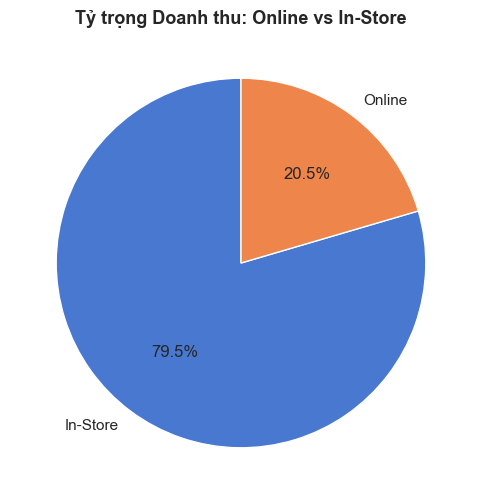

In [259]:
plt.figure(figsize=(6, 6))
plt.pie(channel_rev, labels=channel_rev.index, autopct='%1.1f%%',startangle=90)
plt.title('Tỷ trọng Doanh thu: Online vs In-Store', fontsize=13, fontweight='bold')
plt.show()


<div style="font-size: 16px;">

- Hiệu quả sinh lời của doanh nghiệp cao
- 80% Doanh thu đến từ Instore tạo ra sự phụ thuộc, chưa có sự phát triển mạnh đa kênh để đảm bảo hoạt động không bị gián đoạn
- Việc mở rộng kênh online sẽ không gây ảnh hưởng đến doanh thu

</div>

In [260]:
summary = revenue[revenue['Channel'] == 'In-Store'].groupby('Country').agg(
                                                                            store_count=('StoreKey', 'nunique'),
                                                                            revenue=('Revenue', 'sum'),
                                                                            total_orders=('Order Number', 'nunique')).reset_index()

summary['avg_revenue_store'] = summary['revenue'] / summary['store_count']
summary['avg_order_store'] = summary['total_orders'] / summary['store_count']
summary = summary.drop(columns=['total_orders']).sort_values('revenue', ascending=False)
summary.round(2)


,Country,store_count,revenue,avg_revenue_store,avg_order_store
7,United States,20,23764425.86,1188221.29,557.65
6,United Kingdom,7,5749769.78,821395.68,397.71
3,Germany,8,4246279.22,530784.90,237.75
1,Canada,3,3611561.79,1203853.93,589.67
0,Australia,5,2099141.07,419828.21,180.20
4,Italy,3,2059086.81,686362.27,296.67
5,Netherlands,4,1591344.48,397836.12,194.00
2,France,7,1229545.95,175649.42,81.57


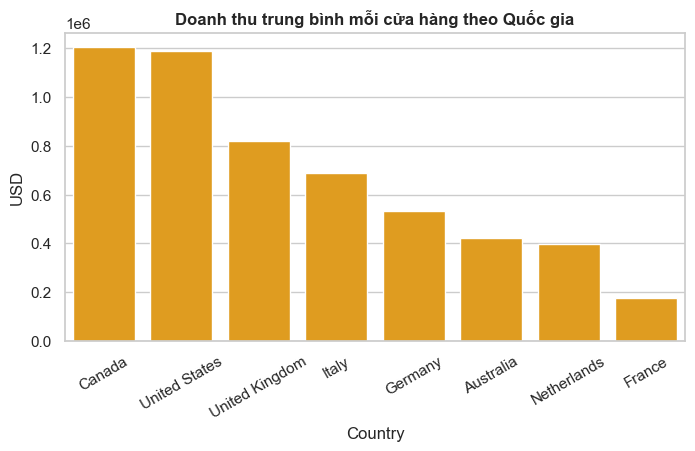

In [261]:
plot_df = summary.sort_values('avg_revenue_store', ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x='Country', y='avg_revenue_store', color='orange')
plt.title('Doanh thu trung bình mỗi cửa hàng theo Quốc gia', fontweight='bold')
plt.ylabel('USD')
plt.xticks(rotation =30)
plt.show()

<div style="font-size: 16px;">

- CANADA là thị trường tiềm năng dù chỉ có 3 cửa hàng nhưng doanh thu và số lượng đơn đứng đầu cho thấy nhu cầu mua sắm cao
- FRANCE có quy mô rộng nhưng lại hoạt động kém hiệu quả nhất

</div>

##### DOANH THU THAY ĐỔI THEO THỜI GIAN

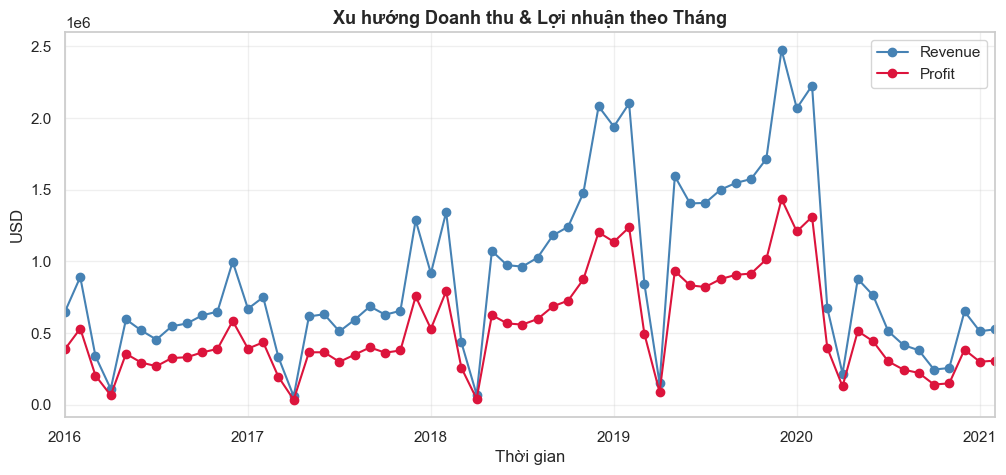

In [262]:
monthly = revenue.resample('ME', on='Order Date')[['Revenue', 'Profit']].sum()
monthly.plot(figsize=(12, 5), color=['steelblue', 'crimson'], marker='o')

plt.title('Xu hướng Doanh thu & Lợi nhuận theo Tháng', fontsize=13, fontweight='bold')
plt.ylabel('USD')
plt.xlabel('Thời gian')
plt.grid(True, alpha=0.3)
plt.show()


<div style="font-size: 16px;">

Xu hướng theo mùa mua sắm tháng 1-2 mua sắm mạnh, tháng 3-4 là vùng chết, tháng 11-12 là thời điểm vàng

</div>

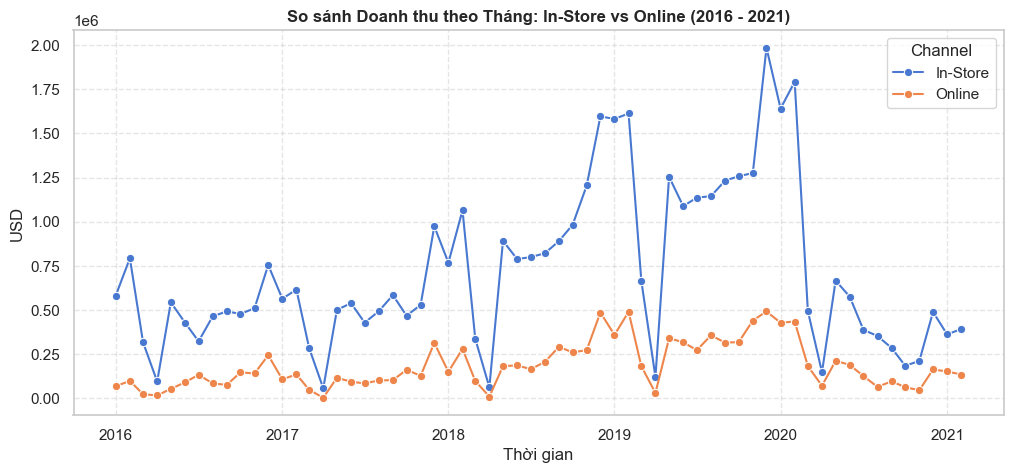

In [263]:
df_trend = revenue.copy()
df_trend['Order Date'] = pd.to_datetime(df_trend['Order Date'])
df_trend['Month'] = df_trend['Order Date'].dt.to_period('M').dt.to_timestamp()

monthly = df_trend.groupby(['Month', 'Channel'])['Revenue'].sum().reset_index()
monthly['Revenue_M'] = monthly['Revenue']

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x='Month', y='Revenue_M', hue='Channel', marker='o')

plt.title('So sánh Doanh thu theo Tháng: In-Store vs Online (2016 - 2021)', fontweight='bold')
plt.xlabel('Thời gian')
plt.ylabel('USD')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


#### Phân tích sản phẩm

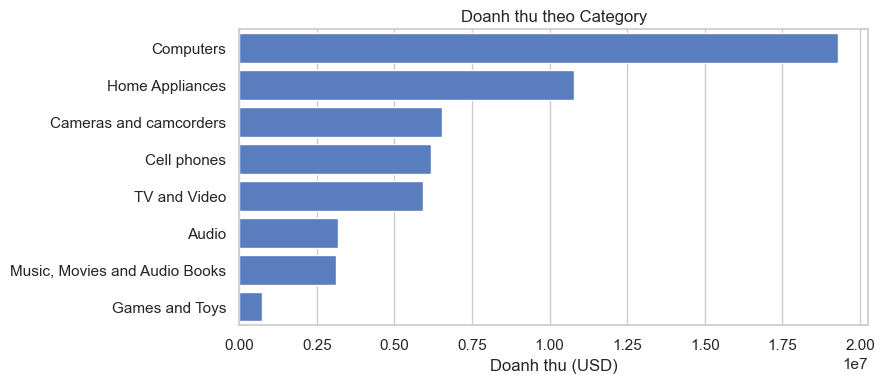

In [264]:
cat_data = (revenue.groupby('Category')['Revenue'].sum().sort_values(ascending=False).reset_index())

plt.figure(figsize=(9, 4))
sns.barplot(data=cat_data, x='Revenue', y='Category')
plt.title('Doanh thu theo Category')
plt.xlabel('Doanh thu (USD)')
plt.ylabel('')
plt.tight_layout()
plt.show()

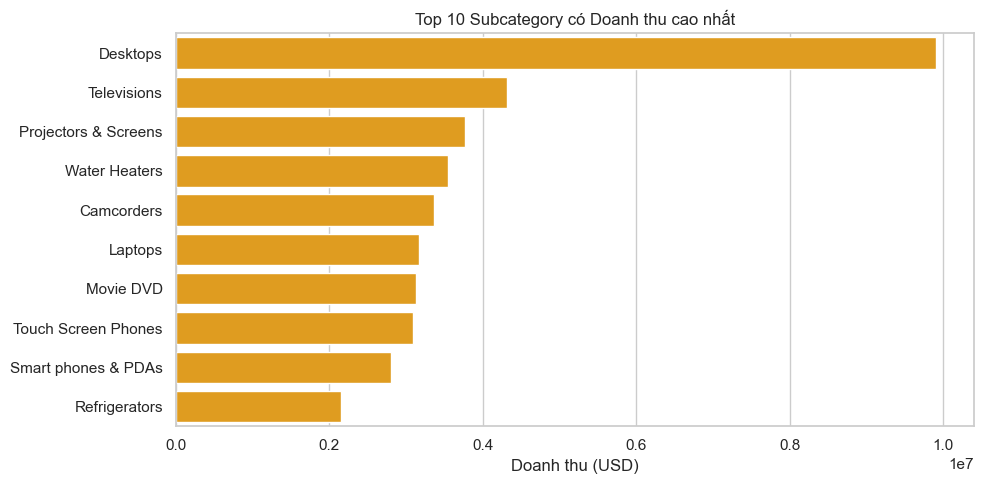

In [265]:
top10_subcat = (revenue.groupby('Subcategory')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index())
plt.figure(figsize=(10, 5))
sns.barplot(data=top10_subcat, x='Revenue', y='Subcategory', color = 'orange')

plt.title('Top 10 Subcategory có Doanh thu cao nhất')
plt.xlabel('Doanh thu (USD)')
plt.ylabel('')
plt.tight_layout()
plt.show()


<div style="font-size: 16px;">

Các sản phẩm thuộc Computer và Home appliance chiếm hơn 50% doanh thu cả doanh nghiệp trong đó Desktops là sản phẩm chính mang lại doanh thu cho doanh nghiệp

</div>

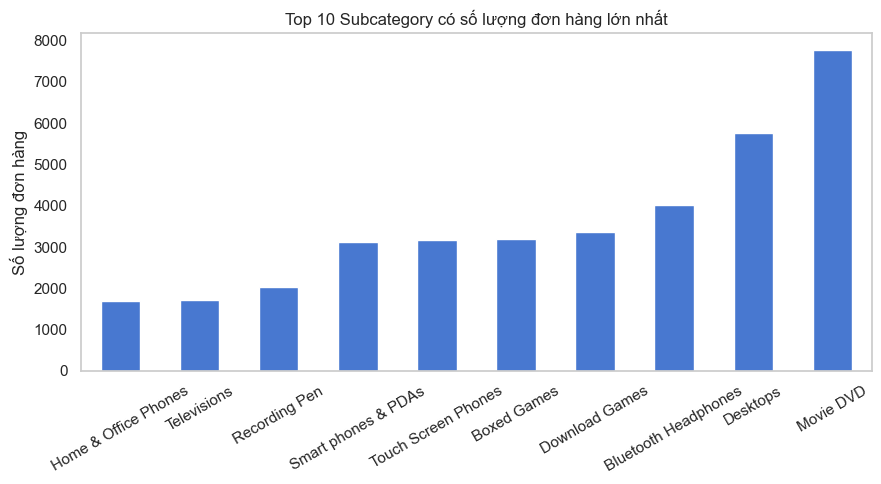

In [266]:
subcat_orders = (revenue.groupby('Subcategory')['Order Number'].nunique().sort_values(ascending=False) .head(10) .sort_values(ascending=True)) 
ax = subcat_orders.plot(kind='bar', figsize=(9, 5))

ax.grid(False)
plt.title('Top 10 Subcategory có số lượng đơn hàng lớn nhất')
plt.xlabel('')
plt.ylabel('Số lượng đơn hàng')
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

<div style="font-size: 16px;">

Movie DVD và Games không tạo ra doanh thu lớn nhưng có khả năng thu hút khách 

</div>

In [267]:
# Lọc bỏ năm 2021 (chỉ lấy các năm có dữ liệu trọn vẹn)
revenue_clean = revenue[revenue['Year'] < 2021]

# Xác định năm mua hàng đầu tiên của từng khách hàng
first_year = revenue_clean.groupby('CustomerKey')['Year'].min()
years = sorted(revenue_clean['Year'].unique())
crr_data = []

# Tính CRR giữa các năm liên tiếp theo công thức: (E - N / S) * 100
for i in range(1, len(years)):
    y_prev, y_curr = years[i - 1], years[i]
    S = revenue_clean[revenue_clean['Year'] == y_prev]['CustomerKey'].nunique()
    E = revenue_clean[revenue_clean['Year'] == y_curr]['CustomerKey'].nunique()
    N = (first_year == y_curr).sum()
    retained = E - N
    crr = (retained / S) * 100 if S > 0 else 0
    crr_data.append({
        'Giai đoạn': f'{y_prev} - {y_curr}',
        'S (Đầu kỳ)': S,
        'E (Cuối kỳ)': E,
        'N (Khách mới)': N,
        'E - N (Khách cũ ở lại)': retained,
        'CRR (%)': round(crr, 2),
    })

df_crr = pd.DataFrame(crr_data)
df_crr


,Giai đoạn,S (Đầu kỳ),E (Cuối kỳ),N (Khách mới),E - N (Khách cũ ở lại),CRR (%)
0,2016 - 2017,2561,2907,2376,531,20.73
1,2017 - 2018,2907,4765,3104,1661,57.14
2,2018 - 2019,4765,6497,2832,3665,76.92
3,2019 - 2020,6497,3868,947,2921,44.96


<div style="font-size: 16px;">

Doanh nghiệp phát triển mạnh tạo  ra một lượng khách hàng trung thành dù có trong giai đoạn dịch năm 2020 vẫn ghi nhận tới 2921 khách hàng cũ

</div>

#### RFM PHÂN NHÓM KHÁCH HÀNG

Dựa trên ngày cuối cùng của cột Order Date của bảng Sale để làm mốc thời gian (snapshot_date)

In [268]:
sale['Order Date'].max()

Timestamp('2021-02-20 00:00:00')

In [269]:
# Mốc thời gian
snapshot_date = pd.to_datetime('2021-02-20')

Độ tuổi hợp đồng để tránh  bias

In [270]:
# Ngày đầu mua của từng khách hàng
contract_age = revenue.groupby('CustomerKey')['Order Date'].min().reset_index(name='Start Date')
# Độ tuổi hợp đồng theo năm
contract_age['contract age'] = (snapshot_date - contract_age['Start Date']).dt.days / 365
contract_age

,CustomerKey,Start Date,contract age
0,301,2019-11-11,1.279452
1,325,2018-01-13,3.106849
2,554,2018-01-04,3.131507
3,1042,2018-03-06,2.964384
4,1314,2017-12-19,3.175342
...,...,...,...
11882,2099383,2018-07-19,2.594521
11883,2099600,2018-08-08,2.539726
11884,2099758,2019-08-31,1.476712
11885,2099862,2020-01-01,1.139726


In [271]:
contract_age[contract_age['contract age'] <= 1].head(3)

,CustomerKey,Start Date,contract age
9,1863,2020-03-11,0.947945
25,6258,2020-12-24,0.158904
37,9456,2020-06-03,0.717808


<div style="font-size: 13px;">

Chuẩn hóa contract age: 
- Khách cũ 3 năm: Doanh thu / 3 (vẫn đúng bản chất)
- Khách cũ 1.5 năm: Doanh thu / 1.5 (vẫn đúng bản chất)
- Khách mới 0.2 năm (vào năm 2021) doanh thu nhân khống: Doanh thu / 0.2  
--> Ép dữ liệu năm 2021 về 1 năm: Doanh thu / 1 thực tế được giữ nguyên, không bị nhân khống.

</div>

In [272]:
contract_age['contract age'] = contract_age['contract age'].clip(lower=1.0) 
contract_age[contract_age['contract age'] <= 1].head(3)

,CustomerKey,Start Date,contract age
9,1863,2020-03-11,1.0
25,6258,2020-12-24,1.0
37,9456,2020-06-03,1.0


<div style="font-size: 13px;">

**TÍNH CHỈ SỐ RFM**
- Recency (Gần đây): Khách hàng mua hàng gần đây hay không?
- Frequency (Tần suất): Khách hàng mua hàng bao nhiêu lần?
- Monetary (Giá trị): Khách hàng đã chi tiêu bao nhiêu tiền?

</div>

In [273]:
rfm_raw = revenue.groupby('CustomerKey').agg(last_purchase = ('Order Date', 'max'),
                                             unique_days = ('Order Date', 'nunique'),
                                             total_revenue = ('Revenue', 'sum')). reset_index()
rfm_raw.head(3)

,CustomerKey,last_purchase,unique_days,total_revenue
0,301,2019-11-11,1,592.00
1,325,2020-01-04,3,5787.67
2,554,2019-12-05,2,951.71


In [274]:
rfm = rfm_raw.merge(contract_age, on ='CustomerKey')

#RECENCY
rfm['Recency'] = (snapshot_date - rfm['last_purchase']).dt.days
#FRECENCY
rfm['Frequency'] = rfm['unique_days'] / rfm['contract age']
#MONETARY
rfm['Monetary'] = rfm['total_revenue'] / rfm['contract age']

rfm = rfm[['CustomerKey', 'Recency', 'Frequency', 'Monetary']]
rfm.head(5)

,CustomerKey,Recency,Frequency,Monetary
0,301,467,0.781585,462.698073
1,325,413,0.965608,1862.874383
2,554,443,0.638670,303.914392
3,1042,1082,0.337338,379.475185
4,1314,1159,0.314927,799.869629


<div style="font-size: 14px;">

Áp dụng khoảng tứ phân vị (IQR) để chia dữ liệu ra làm 4 phần bằng nhau để xếp hạng từ 1- 4

</div>

In [275]:
# Lấy các mốc 25% (Q1), 50% (Q2), 75% (Q3)
q_R = rfm['Recency'].quantile([0.25, 0.5, 0.75])
q_F = rfm['Frequency'].quantile([0.25, 0.5, 0.75])
q_M = rfm['Monetary'].quantile([0.25, 0.5, 0.75])

# Chấm điểm R (Recency NHỎ là tốt -> 4 điểm)
rfm['R'] = rfm['Recency'].apply(lambda x: 4 if x < q_R[0.25] else (3 if x < q_R[0.5] else (2 if x < q_R[0.75] else 1)))
# Chấm điểm F và M (F, M LỚN là tốt -> 4 điểm)
rfm['F'] = rfm['Frequency'].apply(lambda x: 1 if x < q_F[0.25] else (2 if x < q_F[0.5] else (3 if x < q_F[0.75] else 4)))
rfm['M'] = rfm['Monetary'].apply(lambda x: 1 if x < q_M[0.25] else (2 if x < q_M[0.5] else (3 if x < q_M[0.75] else 4)))

rfm.head(3)

,CustomerKey,Recency,Frequency,Monetary,R,F,M
0,301,467,0.781585,462.698073,3,3,2
1,325,413,0.965608,1862.874383,3,3,3
2,554,443,0.638670,303.914392,3,2,1


<div style="font-size: 13px;">

ÁP DỤNG MA TRẬN BCG MATRIX 
- Star: khách hàng vip  | R ∈ [3,4] & F ∈ [3,4] & M ∈ [3,4] | VIP hoàn hảo — mua gần, mua nhiều, chi nhiều |
- Question mark: Khách hàng tiềm năng  | M ∈ [3,4] *(nhưng không phải Star)* | Chi tiêu cao nhưng thiếu tần suất hoặc gần đây |
- Cash cow: Khách hàng trung thành  | F ∈ [3,4] & M ∈ [1,2] | Trung thành, mua đều đặn nhưng giỏ hàng nhỏ |
- Dog: Khách hàng vãng lai  | Còn lại | Vãng lai — mua ít, chi ít |

</div>

In [276]:
# Gộp thành cột RFM
rfm['RFM_Code'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

rfm['BCG_Matrix'] = rfm.apply(lambda row: 'Star' if (row['M'] >= 3 and row['F'] >= 3 and row['R'] >= 3) 
    else ('Question Mark' if row['M'] >= 3 
    else ('Cash Cow' if row['F'] >= 3 
    else 'Dog')), axis=1)
rfm.head(5)

,CustomerKey,Recency,Frequency,Monetary,R,F,M,RFM_Code,BCG_Matrix
0,301,467,0.781585,462.698073,3,3,2,332,Cash Cow
1,325,413,0.965608,1862.874383,3,3,3,333,Star
2,554,443,0.638670,303.914392,3,2,1,321,Dog
3,1042,1082,0.337338,379.475185,1,1,1,111,Dog
4,1314,1159,0.314927,799.869629,1,1,2,112,Dog


In [277]:
# Bảng tổng hợp BCG Matrix
bcg_summary = rfm.groupby('BCG_Matrix').agg({'RFM_Code': 'unique', 'CustomerKey': 'count'}).reset_index()
bcg_summary

,BCG_Matrix,RFM_Code,CustomerKey
0,Cash Cow,"[332, 331, 432, 431, 142, 231, 442, 342, 132, 341, 232, 441, 242, 131, 241, 141]",1871
1,Dog,"[321, 111, 112, 221, 421, 211, 222, 422, 212, 122, 322, 311, 121, 312, 412, 411]",4072
2,Question Mark,"[223, 123, 124, 114, 113, 214, 233, 324, 224, 213, 243, 133, 234, 323, 244, 424, 423, 313, 134, 413, 414, 144, 314, 143]",2676
3,Star,"[333, 444, 433, 443, 434, 343, 334, 344]",3268


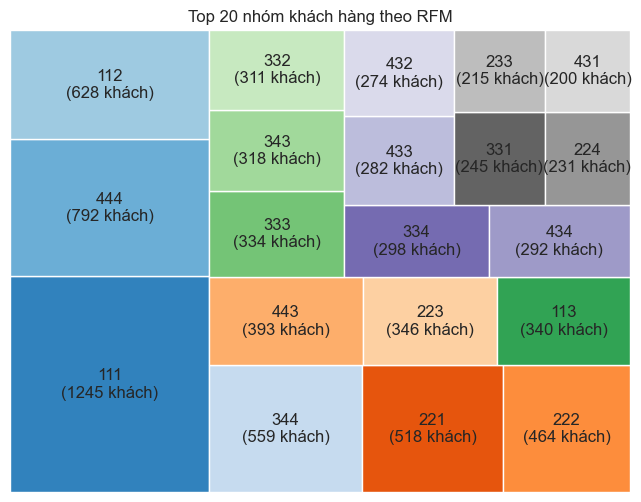

In [291]:
v = rfm['RFM_Code'].value_counts().head(20)
labels =  v.index + '\n(' + v.astype(str) + ' khách)'
plt.figure(figsize=(8, 6))
squarify.plot(sizes=v, label=labels, color=plt.cm.tab20c.colors)
plt.title('Top 20 nhóm khách hàng theo RFM')
plt.axis('off')
plt.show()
